# Training e test: il modello ha imparato davvero?

*Coding e Fondamenti di Intelligenza Artificiale · A.A. 2026/27 · Lezione 12*

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vincnardelli/cia/blob/main/codice/12/lezione_12.ipynb)

Nella lezione 11 l'albero ha trovato da solo le soglie dell'autovelox e ha dato la multa giusta a tutte le 5.000 auto. Ma quelle 5.000 auto le aveva già viste: da lì aveva imparato. Oggi vediamo come si misura se un modello ha imparato **davvero**, su due esempi: le multe e le vendite di seggiolini per auto.

## 1. Perché serve il test

Un modello si costruisce per usarlo su **casi nuovi**: le auto che passeranno domani davanti all'autovelox, i negozi che apriremo l'anno prossimo. Misurarlo sugli stessi esempi da cui ha imparato è come dare un esame con le stesse domande dell'esercitazione: uno studente che le ha imparate a memoria prende il massimo senza aver capito niente.

Per questo i dati si dividono in due parti, **prima** di cominciare:

- **training**: gli esempi da cui il modello impara (di solito il 70–80 %);
- **test**: gli esempi tenuti da parte, che il modello non vede mai mentre impara. Servono solo a misurare quanto sbaglia su casi nuovi.

In scikit-learn la divisione la fa `train_test_split`, il modello impara con `fit` sul training, e `score` dà l'**accuracy**, la quota di risposte giuste.

## 2. Le multe con 30 esempi

Rileggiamo le multe e prepariamo X (la differenza tra velocità e limite) e y (la multa), come nella lezione 11.

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split

autovelox = pd.read_csv("https://www.vincnardelli.com/cia/dati/autovelox.csv")
autovelox["Differenza"] = autovelox["Velocita"] - autovelox["Limite"]

X = autovelox[["Differenza"]]
y = autovelox["Multa"]

Un albero che ha visto solo **30 multe**; le altre 4.970 fanno da test.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=30, random_state=1)
len(X_train), len(X_test)

(30, 4970)

In [3]:
albero_30 = DecisionTreeClassifier(random_state=1)
albero_30.fit(X_train, y_train)

print(export_text(albero_30, feature_names=["Differenza"]))

|--- Differenza <= -3.50
|   |--- class: 0
|--- Differenza >  -3.50
|   |--- Differenza <= 40.00
|   |   |--- Differenza <= 12.00
|   |   |   |--- class: 36
|   |   |--- Differenza >  12.00
|   |   |   |--- class: 148
|   |--- Differenza >  40.00
|   |   |--- Differenza <= 65.00
|   |   |   |--- class: 370
|   |   |--- Differenza >  65.00
|   |   |   |--- class: 500



In [4]:
# L'accuracy è la quota di multe indovinate
albero_30.score(X_train, y_train), albero_30.score(X_test, y_test)

(1.0, 0.9261569416498994)

Sul training l'albero ha il **100 %**: le sue 30 multe le sa a memoria. Sul test scende al **92,6 %**: su 4.970 auto nuove ne sbaglia 367. E le soglie non sono quelle della legge: −3,5 · 12 · 40 · 65 invece di 0 · 10 · 40 · 60. Con 30 esempi non poteva sapere dove passa esattamente il confine: mette la soglia a metà strada tra gli esempi che ha.

In [5]:
# Dove sbaglia? Le multe del test indovinate male
test = X_test.copy()
test["vera"] = y_test
test["prevista"] = albero_30.predict(X_test)

sbagliate = test[test["vera"] != test["prevista"]]
sbagliate.groupby(["vera", "prevista"])["Differenza"].agg(["count", "min", "max"])

,,count,min,max
vera,prevista,,,
0,36,182,-3,0
148,36,89,11,12
500,370,96,61,65


Gli errori stanno tutti vicino ai confini:

- **182** auto tra 3 km/h sotto il limite e il limite stesso prendono una multa da 36 € senza aver superato il limite;
- **89** auto a 11–12 km/h oltre il limite pagano 36 € invece di 148 €;
- **96** auto tra 61 e 65 km/h oltre pagano 370 € invece di 500 €.

Lontano dalle soglie l'albero non sbaglia mai: dove ha visto pochi esempi, indovina.

### Con più esempi, soglie migliori

Ripetiamo con 10, 20, 30, … fino a 3.500 multe nel training (il 70 % del file), e ogni volta misuriamo l'accuracy sul test.

In [6]:
risultati = []
for n in [10, 20, 30, 50, 100, 200, 500, 1000, 3500]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=n, random_state=1)
    albero_n = DecisionTreeClassifier(random_state=1).fit(X_train, y_train)
    risultati.append({"multe_training": n,
                      "accuracy_training": albero_n.score(X_train, y_train),
                      "accuracy_test": albero_n.score(X_test, y_test)})

risultati = pd.DataFrame(risultati)
risultati

,multe_training,accuracy_training,accuracy_test
0,10,1.0,0.836673
1,20,1.0,0.936345
2,30,1.0,0.926157
3,50,1.0,0.932727
4,100,1.0,0.969184
5,200,1.0,0.992917
6,500,1.0,1.000000
7,1000,1.0,1.000000
8,3500,1.0,1.000000


In Python esiste anche ggplot: il pacchetto si chiama **plotnine** e la grammatica è la stessa (i nomi delle colonne vanno tra virgolette, e il grafico intero tra parentesi).

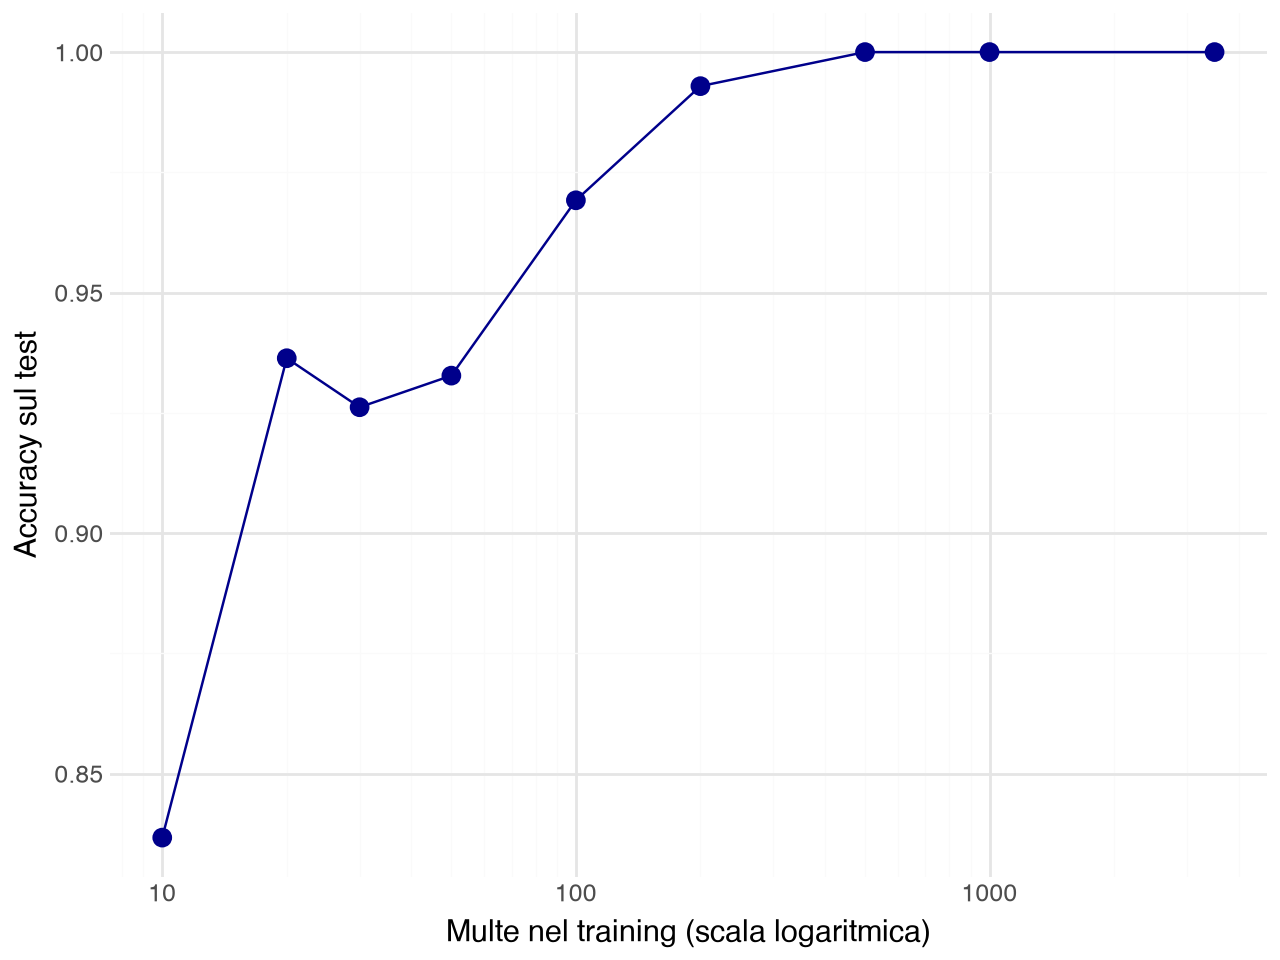

In [7]:
from plotnine import ggplot, aes, geom_line, geom_point, geom_hline, scale_x_log10, theme_minimal, labs

(ggplot(risultati, aes(x="multe_training", y="accuracy_test"))
 + geom_line(color="darkblue")
 + geom_point(color="darkblue", size=3)
 + scale_x_log10()
 + theme_minimal()
 + labs(x="Multe nel training (scala logaritmica)", y="Accuracy sul test"))

Con 10 multe l'albero indovina l'84 % delle auto nuove; con 100 il 97 %; da 500 in su il 100 %. L'accuracy sul training è sempre 1, qualunque sia il numero di esempi: per questo non dice niente.

## 3. I seggiolini per auto

Il secondo esempio è più vicino a un problema di business. Un'azienda vende seggiolini per auto in **400 negozi**: per ogni negozio sappiamo quanto ha venduto (in migliaia di pezzi), il prezzo, il budget di pubblicità locale, la posizione sullo scaffale, e qualcosa sulla zona (reddito, età, popolazione).

**Domanda:** guardando prezzo e pubblicità, sappiamo dire in anticipo quali negozi avranno **vendite alte** (più di 8.000 pezzi)?

A differenza delle multe, qui non esiste una regola esatta: due negozi con lo stesso prezzo e la stessa pubblicità possono vendere in modo diverso.

In [8]:
seggiolini = pd.read_csv("https://www.vincnardelli.com/cia/dati/seggiolini.csv")
seggiolini.head()

,negozio,vendite,prezzo,prezzo_concorrenza,pubblicita,scaffale,reddito,popolazione,eta,istruzione,citta,usa
0,1,9.50,120,138,11,cattivo,73,276,42,17,si,si
1,2,11.22,83,111,16,buono,48,260,65,10,si,si
2,3,10.06,80,113,10,medio,35,269,59,12,si,si
3,4,7.40,97,117,4,medio,100,466,55,14,si,si
4,5,4.15,128,141,3,cattivo,64,340,38,13,si,no


In [9]:
seggiolini.shape

(400, 12)

In [10]:
# La colonna da prevedere la creiamo noi: 1 se le vendite superano 8 (mila pezzi), 0 altrimenti
seggiolini["vendite_alte"] = (seggiolini["vendite"] > 8).astype(int)
seggiolini["vendite_alte"].value_counts()

vendite_alte
0    236
1    164
Name: count, dtype: int64

In [11]:
# Prezzo e pubblicità medi nei negozi con vendite basse (0) e alte (1)
seggiolini.groupby("vendite_alte")[["prezzo", "pubblicita"]].mean()

,prezzo,pubblicita
vendite_alte,,
0,122.588983,5.012712
1,106.018293,8.969512


I negozi che vendono molto hanno in media un prezzo più basso e più pubblicità. Ma è una media: per il singolo negozio l'albero deve trovare le soglie.

Dividiamo **prima** di allenare: 70 % training, 30 % test.

In [12]:
X = seggiolini[["prezzo", "pubblicita"]]
y = seggiolini["vendite_alte"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
len(X_train), len(X_test)

(280, 120)

Prima di qualunque modello, un confronto: un «modello» che dice sempre *vendite basse* quanti negozi del test indovina?

In [13]:
(y_test == 0).mean()

np.float64(0.5833333333333334)

Il **58,3 %**: 70 negozi su 120 hanno vendite basse, e chi dice sempre «basse» li indovina tutti. Un modello vale qualcosa solo se fa meglio di così.

In [14]:
albero_2 = DecisionTreeClassifier(max_depth=2, random_state=1)
albero_2.fit(X_train, y_train)

print(export_text(albero_2, feature_names=["prezzo", "pubblicita"]))

|--- pubblicita <= 6.50
|   |--- prezzo <= 90.50
|   |   |--- class: 1
|   |--- prezzo >  90.50
|   |   |--- class: 0
|--- pubblicita >  6.50
|   |--- prezzo <= 136.00
|   |   |--- class: 1
|   |--- prezzo >  136.00
|   |   |--- class: 0



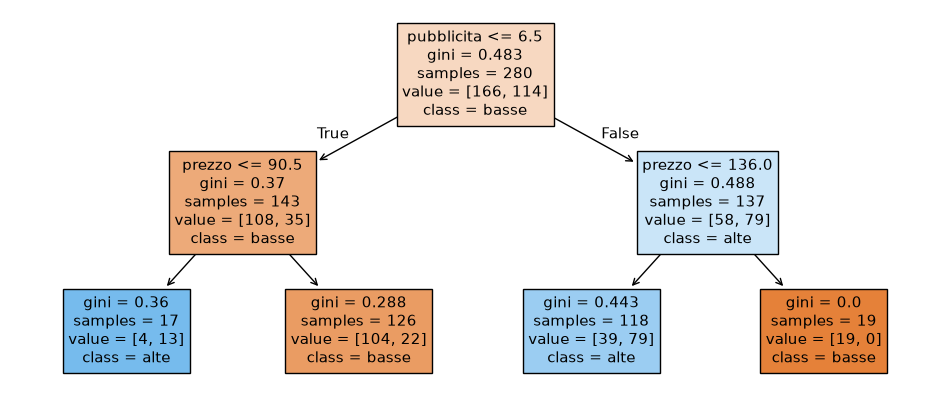

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plot_tree(albero_2, feature_names=["prezzo", "pubblicita"],
          class_names=["basse", "alte"], filled=True, fontsize=11)
plt.show()

`max_depth=2` vuol dire: al massimo due domande di fila. L'albero si legge dall'alto; a ogni domanda si va a sinistra se la risposta è sì.

Prima domanda: la pubblicità è al massimo 6,5 (migliaia di dollari)? Se sì, il negozio vende molto solo con un prezzo molto basso (fino a 90,5). Se la pubblicità è di più, basta un prezzo non troppo alto (fino a 136). Le soglie le ha trovate l'albero, non noi.

In [16]:
albero_2.score(X_train, y_train), albero_2.score(X_test, y_test)

(0.7678571428571429, 0.675)

76,8 % sul training, **67,5 %** sul test: più basso, come sempre, ma meglio del 58,3 % di chi dice sempre «basse».

### Dove sbaglia: la tabella di confusione

L'accuracy è un numero solo. La **tabella di confusione** dice *come* sbaglia: per ogni negozio del test, la classe vera (righe) e quella prevista (colonne). È la `table()` di R.

In [17]:
previste = albero_2.predict(X_test)
pd.crosstab(y_test, previste, rownames=["vere"], colnames=["previste"])

previste,0,1
vere,,
0,49,21
1,18,32


Dei 120 negozi del test:

- **49 + 32 = 81** risposte giuste (il 67,5 %): vendite basse previste basse, alte previste alte;
- **21** negozi con vendite basse che l'albero dà per alte: se puntassimo su quei negozi, resteremmo delusi;
- **18** negozi con vendite alte che l'albero non riconosce: occasioni perse.

I due errori non costano uguale: dipende da cosa ci facciamo con la previsione.

## 4. Più profondo non vuol dire migliore

Lasciamo crescere l'albero senza limiti: può fare tutte le domande che vuole.

In [18]:
albero_tutto = DecisionTreeClassifier(random_state=1)
albero_tutto.fit(X_train, y_train)

albero_tutto.get_n_leaves(), albero_tutto.score(X_train, y_train), albero_tutto.score(X_test, y_test)

(np.int64(103), 0.9642857142857143, 0.6083333333333333)

**103 foglie**, il **96,4 %** sul training… e il **60,8 %** sul test, appena sopra il 58,3 % di chi dice sempre «basse». Con 280 negozi e 103 foglie, ogni foglia contiene due o tre negozi: l'albero ha imparato a memoria il training, compresi i casi strani che nei negozi nuovi non si ripetono. Si chiama **overfitting**.

Proviamo tutte le profondità da 1 a 12 e confrontiamo training e test.

In [19]:
profondita = []
for d in range(1, 13):
    albero_d = DecisionTreeClassifier(max_depth=d, random_state=1).fit(X_train, y_train)
    profondita.append({"profondita": d,
                       "training": albero_d.score(X_train, y_train),
                       "test": albero_d.score(X_test, y_test)})

profondita = pd.DataFrame(profondita)
profondita

,profondita,training,test
0,1,0.667857,0.616667
1,2,0.767857,0.675000
2,3,0.767857,0.675000
3,4,0.771429,0.666667
4,5,0.792857,0.658333
5,6,0.817857,0.625000
6,7,0.853571,0.591667
7,8,0.871429,0.575000
8,9,0.903571,0.608333
9,10,0.932143,0.583333


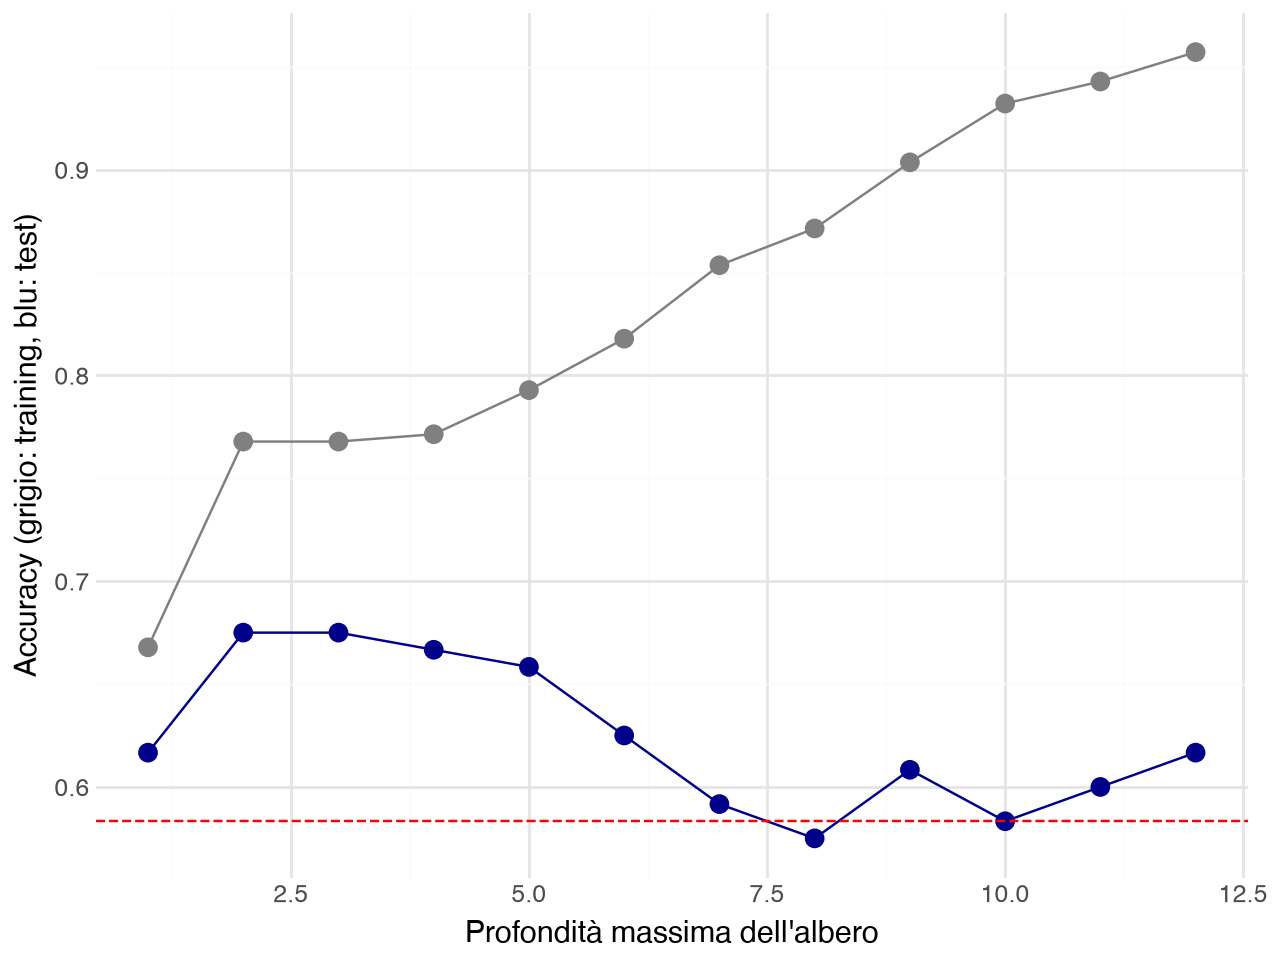

In [20]:
(ggplot(profondita, aes(x="profondita"))
 + geom_line(aes(y="training"), color="grey")
 + geom_point(aes(y="training"), color="grey", size=3)
 + geom_line(aes(y="test"), color="darkblue")
 + geom_point(aes(y="test"), color="darkblue", size=3)
 + geom_hline(yintercept=(y_test == 0).mean(), linetype="dashed", color="red")
 + theme_minimal()
 + labs(x="Profondità massima dell'albero", y="Accuracy (grigio: training, blu: test)"))

Il training (grigio) sale sempre: più domande, più negozi imparati a memoria. Il test (blu) arriva al 67,5 % con profondità 2 e 3, poi scende: le domande in più servono solo a ricordare il training. La linea rossa è il 58,3 % di chi dice sempre «basse». È il test a dirci dove fermarci.

## Cosa abbiamo imparato

1. Un modello si giudica su dati che **non ha visto**: si dividono i dati in training e test prima di cominciare.
2. L'accuracy sul training è sempre ottimista; quella sul test dice come andrà sui casi nuovi.
3. Con pochi esempi le soglie sono approssimative (le multe); con troppe domande l'albero impara a memoria anche il rumore (i seggiolini): è l'**overfitting**.
4. La tabella di confusione dice come sbaglia il modello, non solo quanto. E il primo confronto è sempre con il modello più stupido: «dico sempre la classe più frequente».

Adesso il lab: `lab_seggiolini.ipynb`.